# EO4FLOOD river width

Satellite-derived river width is one of the quantities related to river discharge. This Ebro
example compares Landsat and Sentinel-2 observations, examines the sampling at a gauge, and
locates the stations represented in the basin-wide Parquet asset. The online asset URL comes
from the EO4FLOOD river-width STAC item.

The product is produced by the Institute of Geodesy (GIS), University of Stuttgart. It contains
multiple stations and satellite missions, with irregular observation times rather than a complete
daily record. Width is a proxy for discharge, not a direct measurement of flow.

| Column | Meaning |
|---|---|
| `time` | Observation timestamp |
| `w` | Estimated river width in metres |
| `gauge_name` | Gauge identifier |
| `reach_ID` | Associated SWORD v17 reach identifier |
| `satellite` | Landsat or Sentinel-2 |
| `gauge_lon`, `gauge_lat` | Gauge location in geographic degrees |

No width-uncertainty column is supplied in this delivery.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

WIDTH_URL = 'https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/eo4flood/width_series/Ebro_width_timeseries.parquet'
BASIN = "Ebro"
GAUGE = "6226400_GRDC"
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True})

width = pd.read_parquet(WIDTH_URL)
for column in ["gauge_name", "reach_ID", "satellite"]:
    width[column] = width[column].str.decode("utf-8")
width = width.sort_values("time")
width.head()

,time,w,basin,gauge_name,gauge_lat,gauge_lon,reach_ID,satellite,title,creation_time,institution,contact,pdate,temporal interval,version,Conventions,DOI,Acknowledgements
0,2016-01-17,75.188348,b'ebro',6226400_GRDC,41.658569,-0.881060,21604500021,Landsat,ESA EO4FLOOD project river width,2026-09-16 16:17:14,"Institute of Geodesy (GIS), University of Stut...",saemian@gis.uni-stuttgart.de; omid.elmi@gis.un...,2026-09-16,17-Jan-2016 to 03-Dec-2025,2.0,CF-1.11-draft,10.5281/zenodo.21699983,ESA EO4FLOOD project reference
0,2016-01-17,505.082996,b'ebro',9257_AFD,42.289719,0.192165,21604200723,Landsat,ESA EO4FLOOD project river width,2026-09-16 16:17:12,"Institute of Geodesy (GIS), University of Stut...",saemian@gis.uni-stuttgart.de; omid.elmi@gis.un...,2026-09-16,17-Jan-2016 to 28-Dec-2025,2.0,CF-1.11-draft,10.5281/zenodo.21699983,ESA EO4FLOOD project reference
1,2016-01-26,465.140584,b'ebro',9257_AFD,42.289719,0.192165,21604200723,Landsat,ESA EO4FLOOD project river width,2026-09-16 16:17:12,"Institute of Geodesy (GIS), University of Stut...",saemian@gis.uni-stuttgart.de; omid.elmi@gis.un...,2026-09-16,17-Jan-2016 to 28-Dec-2025,2.0,CF-1.11-draft,10.5281/zenodo.21699983,ESA EO4FLOOD project reference
0,2016-02-21,281.603465,b'ebro',9210_AFD,41.243336,0.434015,21604100144,Sentinel-2,ESA EO4FLOOD project river width,2026-09-16 16:17:18,"Institute of Geodesy (GIS), University of Stut...",saemian@gis.uni-stuttgart.de; omid.elmi@gis.un...,2026-09-16,21-Feb-2016 to 30-Dec-2025,2.0,CF-1.11-draft,10.5281/zenodo.21699983,ESA EO4FLOOD project reference
0,2016-02-21,51.196997,b'ebro',6226600_GRDC,41.452888,0.419710,21604200061,Sentinel-2,ESA EO4FLOOD project river width,2026-09-16 16:17:14,"Institute of Geodesy (GIS), University of Stut...",saemian@gis.uni-stuttgart.de; omid.elmi@gis.un...,2026-09-16,21-Feb-2016 to 05-Dec-2025,2.0,CF-1.11-draft,10.5281/zenodo.21699983,ESA EO4FLOOD project reference


## Stations and observations

The inventory distinguishes gauge locations from satellite observations: two missions may observe
the same reach at different times. Counts and date ranges describe the observations available for
each station–mission pair. Spatial differences in width also reflect river geometry, so a wide
river at one station does not establish higher discharge than a narrow river elsewhere.

observations      first       last  median_width_m
gauge_name   satellite                                                     
6226400_GRDC Landsat              320 2016-01-17 2025-12-03       69.450924
             Sentinel-2           108 2017-04-09 2025-12-03       70.160080
6226600_GRDC Landsat               51 2017-08-24 2025-11-25       45.010950
             Sentinel-2           340 2016-02-21 2025-12-05       45.771738
6226800_GRDC Landsat              311 2016-03-05 2025-12-19       87.376881
             Sentinel-2            52 2017-03-17 2025-11-25       89.221916
9002_AFD     Landsat               93 2016-07-18 2025-12-18       53.667543
             Sentinel-2            15 2018-07-08 2025-07-11       61.610243
9027_AFD     Landsat              310 2016-03-05 2025-12-19       71.312131
             Sentinel-2            50 2017-03-17 2025-11-25       73.866835
9029_AFD     Landsat               53 2017-03-17 2025-10-01      222.358841
             Sentinel-2           363 2016-02-21 2025-12-30      229.027521
9112_AFD     Landsat               29 2018-03-27 2025-11-25       42.616770
             Sentinel-2           374 2016-02-21 2025-12-30       43.688176
9162_AFD     Landsat               21 2018-01-29 2025-08-20       49.757894
             Sentinel-2           312 2016-05-04 2025-12-23       46.268251
9210_AFD     Landsat               58 2017-03-17 2025-11-25      257.106336
             Sentinel-2           393 2016-02-21 2025-12-30      259.166903
9257_AFD     Landsat              304 2016-01-17 2025-12-28      528.245852
             Sentinel-2            38 2017-11-12 2025-07-28      521.317497
9258_AFD     Landsat               52 2017-03-17 2025-12-12       30.000000
             Sentinel-2           364 2016-02-21 2025-12-30       30.000000
9263_AFD     Landsat              154 2016-04-06 2025-12-03       89.251413
             Sentinel-2            60 2017-04-09 2025-12-03       90.047072
9281_AFD     Landsat               31 2016-06-23 2025-12-01       40.053161
             Sentinel-2           525 2016-05-04 2025-12-28       40.458565

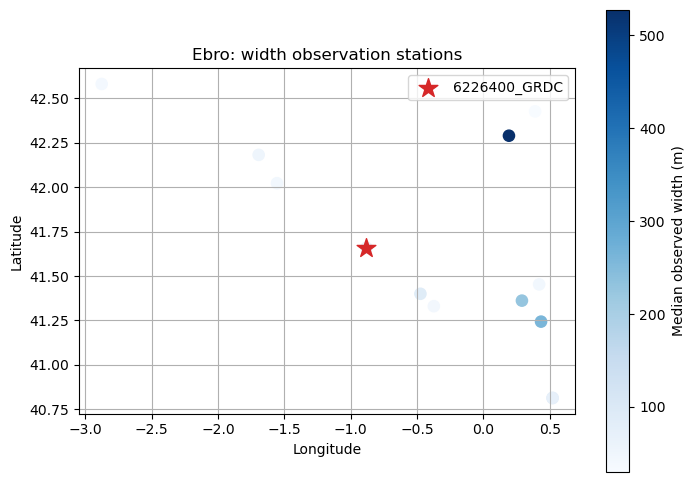

In [2]:
inventory = width.groupby(["gauge_name", "satellite"]).agg(
    observations=("w", "count"), first=("time", "min"), last=("time", "max"),
    median_width_m=("w", "median")
)
display(inventory)
stations = width.groupby("gauge_name").agg(
    longitude=("gauge_lon", "first"), latitude=("gauge_lat", "first"),
    median_width_m=("w", "median")
)
fig, ax = plt.subplots(figsize=(8, 6))
points = ax.scatter(stations.longitude, stations.latitude, c=stations.median_width_m, cmap="Blues", s=65)
fig.colorbar(points, ax=ax, label="Median observed width (m)")
ax.scatter(stations.loc[GAUGE, "longitude"], stations.loc[GAUGE, "latitude"],
           marker="*", s=200, color="tab:red", label=GAUGE)
ax.set(xlabel="Longitude", ylabel="Latitude", title=f"{BASIN}: width observation stations")
ax.set_aspect(1 / np.cos(np.deg2rad(stations.latitude.mean())))
ax.legend()
plt.show()

## Width through time at Zaragoza

Gauge 6226400_GRDC illustrates the two mission series at one location. Individual markers retain
the actual observation dates. No interpolation is applied across gaps. Differences can arise from
river conditions, acquisition dates, spatial resolution and the measurement method; these series
are not a set of simultaneous cross-sensor observations.

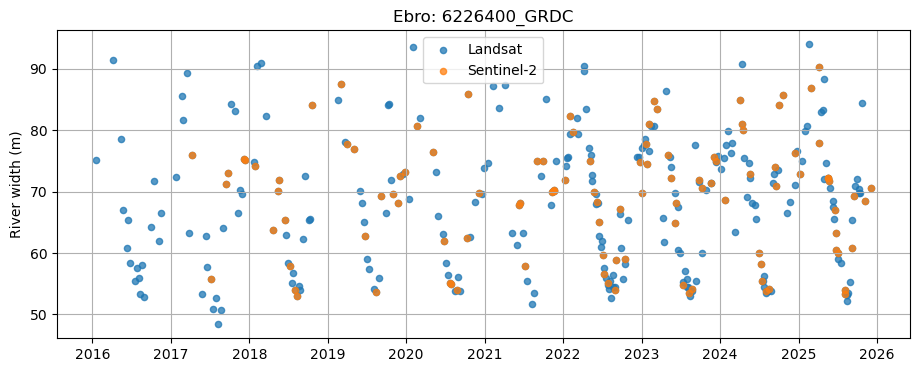

,count,mean,std,min,25%,50%,75%,max
satellite,,,,,,,,
Landsat,320.0,68.426407,10.520805,48.379540,58.371762,69.450924,75.509976,94.009530
Sentinel-2,108.0,69.124348,9.572402,53.028381,60.749586,70.160080,75.069647,90.357784


In [3]:
station = width.loc[width.gauge_name == GAUGE]
fig, ax = plt.subplots()
for mission, observations in station.groupby("satellite"):
    ax.scatter(observations.time, observations.w, s=20, alpha=0.75, label=mission)
ax.set(ylabel="River width (m)", title=f"{BASIN}: {GAUGE}")
ax.legend()
plt.show()
display(station.groupby("satellite").w.describe())

## Monthly behaviour and sampling

Monthly medians reduce the influence of isolated observations while leaving unobserved months
empty. The count panel shows how much evidence supports each monthly summary. Missions with
unequal sampling may represent different parts of a month's hydrological conditions.

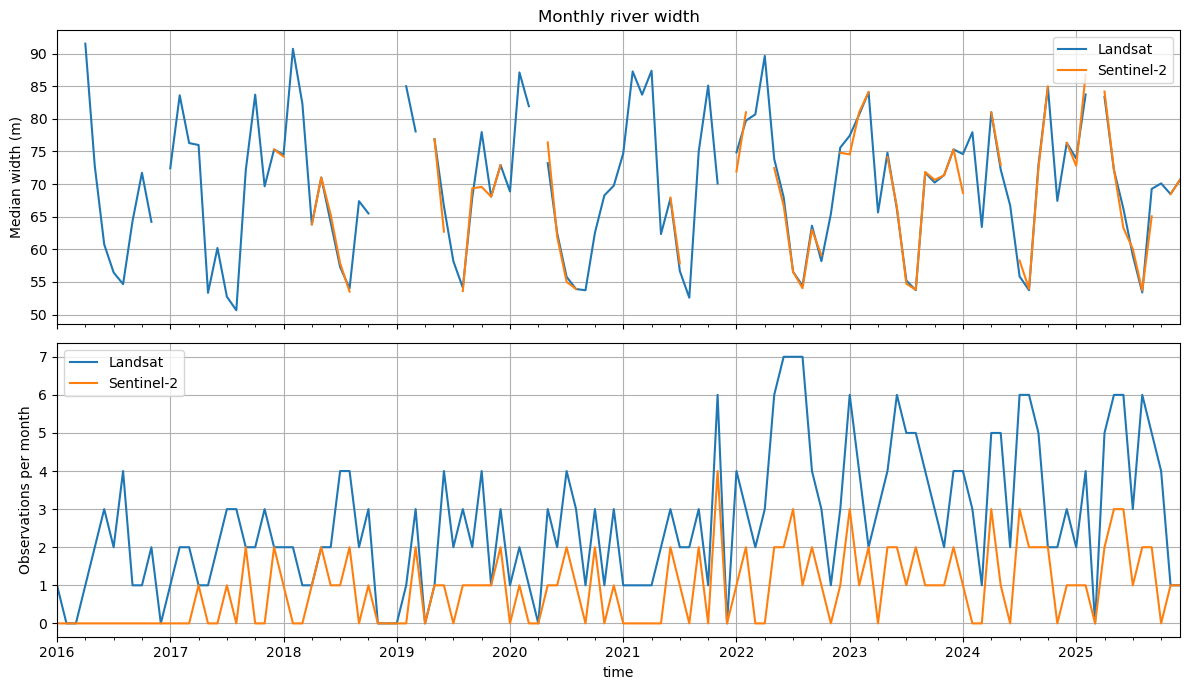

In [5]:
monthly = {}
counts = {}
for mission, observations in station.groupby("satellite"):
    series = observations.set_index("time").w
    monthly[mission] = series.resample("MS").median()
    counts[mission] = series.resample("MS").count()
monthly = pd.DataFrame(monthly)
counts = pd.DataFrame(counts).fillna(0)
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(12, 7))
monthly.plot(ax=axes[0], ylabel="Median width (m)", title="Monthly river width")
counts.plot(ax=axes[1], ylabel="Observations per month")
fig.tight_layout()
plt.show()

## Seasonal pattern

The seasonal curve is the mean of available monthly medians for each calendar month. It describes
this observation record rather than an evenly sampled climatology. A seasonal width pattern may
reflect changing flow conditions, but this demonstration does not convert width into discharge.

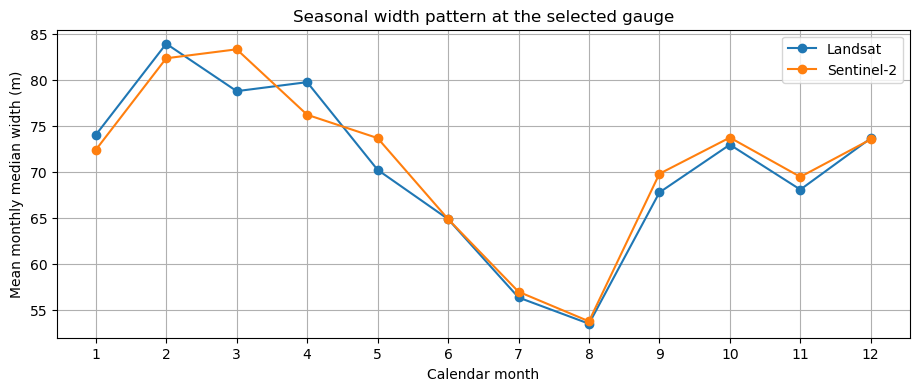

In [6]:
monthly.groupby(monthly.index.month).mean().plot(
    marker="o", xlabel="Calendar month", ylabel="Mean monthly median width (m)",
    title="Seasonal width pattern at the selected gauge", xticks=range(1, 13))
plt.show()